# 降维

### 问题

特征一多就麻烦:画不出图,距离算出来没意义,模型也变慢。降维就是想用少数几个新特征把原来大部分信息保住。

PCA 的做法是找一组正交方向,把数据投影上去,让投影后的方差尽量大。方差大意味着这些方向上的差异保留得多,方差接近 0 的方向基本就是噪声,可以扔掉。

数学上就是对中心化后的数据做 SVD。设 X 是 n×d 的矩阵,中心化之后

$$X=U\Sigma V^T$$

V 的列就是主成分方向,$\sigma_i^2 / \sum \sigma_j^2$ 就是第 i 个主成分解释的方差比例。

PCA 是线性的,也只能保证方差最大,不代表留下来的就是有用的方向,这是它和判别式降维的区别。

## 1. 数据

iris,4 个特征。4 维还能画,但先拿它练手,后面再上 30 维的乳腺癌数据。

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

X, y = load_iris(return_X_y=True)
Xs = StandardScaler().fit_transform(X)

print("原始各特征标准差:", X.std(axis=0).round(2))
print("标准化后:", Xs.std(axis=0).round(2))

原始各特征标准差: [0.83 0.43 1.76 0.76]
标准化后: [1. 1. 1. 1.]


## 2. 手写一遍 PCA

中心化之后做 SVD,拿奇异值平方算解释方差比例,再和 sklearn 对一下。

In [2]:
from sklearn.decomposition import PCA

Z = Xs - Xs.mean(axis=0)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)

evr_hand = S ** 2 / (S ** 2).sum()
pca = PCA().fit(Xs)

print("手算:", evr_hand.round(4))
print("sklearn:", pca.explained_variance_ratio_.round(4))

手算: [0.7296 0.2285 0.0367 0.0052]
sklearn: [0.7296 0.2285 0.0367 0.0052]


一行代码就能对上。主成分本身可能会差一个符号,因为 V 和 -V 都对,sklearn 内部做了统一。这不是 bug,只要不用系数去解释方向就不用管。

## 3. 解释方差

4 个主成分各解释多少,累加起来够不够。

In [3]:
cum = np.cumsum(pca.explained_variance_ratio_)
for i, (r, c) in enumerate(zip(pca.explained_variance_ratio_, cum), 1):
    print(f"PC{i}: {r:.4f}  累计 {c:.4f}")

PC1: 0.7296  累计 0.7296
PC2: 0.2285  累计 0.9581
PC3: 0.0367  累计 0.9948
PC4: 0.0052  累计 1.0000


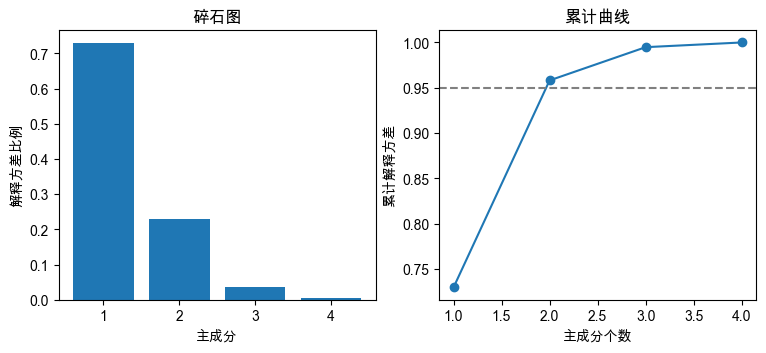

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

axs[0].bar(range(1, 5), pca.explained_variance_ratio_)
axs[0].set_xlabel("主成分")
axs[0].set_ylabel("解释方差比例")
axs[0].set_title("碎石图")

axs[1].plot(range(1, 5), cum, marker="o")
axs[1].axhline(0.95, color="gray", linestyle="--")
axs[1].set_xlabel("主成分个数")
axs[1].set_ylabel("累计解释方差")
axs[1].set_title("累计曲线")

plt.show()

第一主成分解释 72.96%,前两个就到 95.81%,后两个加起来不到 5%,基本可以扔掉。4 维降到 2 维,信息保留得还不错。

实际选主成分个数常用两种办法:看累计解释方差到 90% 或 95%,或者看碎石图从哪开始变平。

## 4. 投影到二维

把数据投到前两个主成分上画出来。

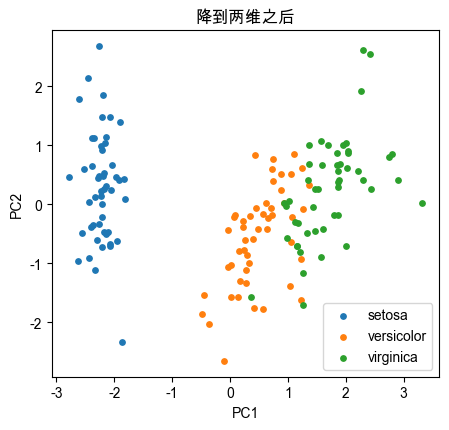

In [5]:
Z2 = pca.transform(Xs)[:, :2]

fig, ax = plt.subplots(figsize=(5, 4.5))
for k, name in enumerate(["setosa", "versicolor", "virginica"]):
    mask = y == k
    ax.scatter(Z2[mask, 0], Z2[mask, 1], s=15, label=name)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("降到两维之后")
ax.legend()
plt.show()

PCA 完全不知道标签,只是按方差找方向,但投影完三类自己就分开了。setosa 在左边单独一坨,另外两类在右边有重叠。

这也说明 iris 的前两个主成分确实抓到了主要结构。不过降维之后再分类不一定更好,因为 PCA 不考虑标签,丢掉的方向可能正好是区分类别的方向。

## 5. 丢掉的信息

只用 n 个主成分,重构回原来的空间,看差多少。

In [6]:
for n in [1, 2, 3, 4]:
    p = PCA(n_components=n).fit(Xs)
    rec = p.inverse_transform(p.transform(Xs))
    print(f"n={n}: 重构 MSE={np.mean((Xs - rec) ** 2):.4f}")

n=1: 重构 MSE=0.2704
n=2: 重构 MSE=0.0419
n=3: 重构 MSE=0.0052
n=4: 重构 MSE=0.0000


1 个主成分的重构误差是 0.2704,2 个降到 0.0419,3 个 0.0052,4 个为 0(信息没丢)。

误差和解释方差是互补的:2 个主成分保住了 95.81% 的方差,剩下的 4.19% 就是这点误差。

## 6. 一定要先标准化

不标准化直接 PCA,结果会完全不一样,因为 PCA 找的是方差最大的方向,量纲大的特征天然占便宜。iris 四种花的测量单位都是厘米,但量级差得很远:花瓣长度标准差 1.76,萼片宽度只有 0.43。

In [7]:
pca_raw = PCA().fit(X)

print("不标准化:", pca_raw.explained_variance_ratio_.round(4))
print("标准化  :", pca.explained_variance_ratio_.round(4))
print()
print("第一主成分(不标准化):", pca_raw.components_[0].round(3))

不标准化: [0.9246 0.0531 0.0171 0.0052]
标准化  : [0.7296 0.2285 0.0367 0.0052]

第一主成分(不标准化): [ 0.361 -0.085  0.857  0.358]


不标准化时第一主成分解释 92.46%,比标准化后的 72.96% 还高,看着更成功,其实是假象:花瓣长度方差 3.1,萼片宽度只有 0.19。第一主成分的载荷是 [0.36, -0.09, 0.86, 0.36],大头压在花瓣长度上,基本就是在比谁的数值大。

标准化之后四个特征的权重相当,第一主成分对应的是整体大小这个方向。想让 PCA 公平对待每个特征,先 `StandardScaler`。

## 7. 高维数据:30 个特征

乳腺癌数据的 30 个特征,降到几个够用?

In [8]:
from sklearn.datasets import load_breast_cancer

X_c, y_c = load_breast_cancer(return_X_y=True)
X_cs = StandardScaler().fit_transform(X_c)
pca_c = PCA().fit(X_cs)
cum_c = np.cumsum(pca_c.explained_variance_ratio_)

for level in [0.8, 0.9, 0.95]:
    n = int(np.searchsorted(cum_c, level) + 1)
    print(f"保留 {level:.0%} 的方差需要 {n} 个主成分")

print("前两个主成分:", round(cum_c[1], 4))

保留 80% 的方差需要 5 个主成分
保留 90% 的方差需要 7 个主成分
保留 95% 的方差需要 10 个主成分
前两个主成分: 0.6324


30 维降到 7 维能保住 90% 的方差,参数量少了四分之三。但前两个主成分只有 63.2%,直接画成二维图会有点挤。

## 8. 小结

- PCA 找的是方差最大的正交方向,等价于对中心化数据做 SVD;
- 主成分个数看累计解释方差,90% 或 95% 是常用的门槛;
- 一定要先标准化,否则结果被量纲大的特征垄断;
- 主成分的符号可以反过来,不影响投影结果;
- PCA 是无监督的,不考虑标签,降维不保证对分类有帮助;
- 线性投影搞不定的非线性结构,要换 t-SNE、UMAP 这些方法。